In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("creditcard.csv")
print(df.shape)
print(df["Class"].value_counts())

(284807, 31)
Class
0    284315
1       492
Name: count, dtype: int64


Missing values: 0
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


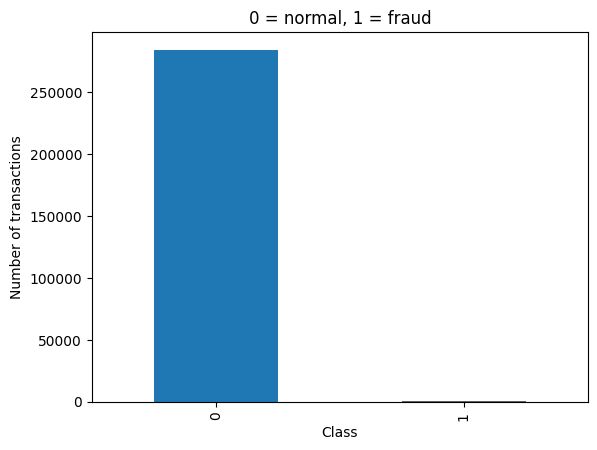

In [2]:
print("Missing values:", df.isnull().sum().sum())
print(df["Class"].value_counts(normalize=True) * 100)

df["Class"].value_counts().plot(kind="bar")
plt.title("0 = normal, 1 = fraud")
plt.xlabel("Class")
plt.ylabel("Number of transactions")
plt.show()

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

X_train = X_train.copy()
X_test = X_test.copy()

scaler = RobustScaler()
X_train[["Amount", "Time"]] = scaler.fit_transform(X_train[["Amount", "Time"]])
X_test[["Amount", "Time"]] = scaler.transform(X_test[["Amount", "Time"]])

print(X_train.shape, X_test.shape)
print("Fraud in train:", y_train.sum(), "| Fraud in test:", y_test.sum())

(227845, 30) (56962, 30)
Fraud in train: 394 | Fraud in test: 98


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, average_precision_score

lr = LogisticRegression(class_weight="balanced", max_iter=1000)
lr.fit(X_train, y_train)

y_pred = lr.predict(X_test)
y_prob = lr.predict_proba(X_test)[:, 1]

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("PR-AUC:", average_precision_score(y_test, y_prob))

[[55476  1388]
 [    8    90]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     56864
           1       0.06      0.92      0.11        98

    accuracy                           0.98     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.98      0.99     56962

PR-AUC: 0.7174539341990154


In [5]:
from sklearn.metrics import precision_recall_curve
import numpy as np

probs = model.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, probs)

# best F1 threshold
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best = np.argmax(f1[:-1])
print("Best threshold:", thr[best])
print("Precision:", prec[best], "Recall:", rec[best], "F1:", f1[best])

# confusion matrix at that threshold
from sklearn.metrics import confusion_matrix
pred = (probs >= thr[best]).astype(int)
print(confusion_matrix(y_test, pred))

NameError: name 'model' is not defined

In [6]:
from sklearn.metrics import precision_recall_curve, confusion_matrix
import numpy as np

prec, rec, thr = precision_recall_curve(y_test, y_prob)

f1 = 2 * prec * rec / (prec + rec + 1e-9)
best = np.argmax(f1[:-1])
print("Best threshold:", thr[best])
print("Precision:", prec[best], "Recall:", rec[best], "F1:", f1[best])

pred = (y_prob >= thr[best]).astype(int)
print(confusion_matrix(y_test, pred))

Best threshold: 0.9999999285486556
Precision: 0.8333333333333334 Recall: 0.8163265306122449 F1: 0.8247422675412902
[[56848    16]
 [   18    80]]


In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, confusion_matrix
import numpy as np

rf = RandomForestClassifier(n_estimators=100, class_weight="balanced", n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)

rf_prob = rf.predict_proba(X_test)[:, 1]
print("RF PR-AUC:", average_precision_score(y_test, rf_prob))

prec, rec, thr = precision_recall_curve(y_test, rf_prob)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best = np.argmax(f1[:-1])
print("Best threshold:", thr[best])
print("Precision:", prec[best], "Recall:", rec[best], "F1:", f1[best])
print(confusion_matrix(y_test, (rf_prob >= thr[best]).astype(int)))

RF PR-AUC: 0.8541999432510914
Best threshold: 0.3
Precision: 0.9222222222222223 Recall: 0.8469387755102041 F1: 0.8829787229051608
[[56857     7]
 [   15    83]]


In [8]:
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, confusion_matrix
import numpy as np

ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                    scale_pos_weight=ratio, eval_metric="aucpr",
                    n_jobs=-1, random_state=42)
xgb.fit(X_train, y_train)

xgb_prob = xgb.predict_proba(X_test)[:, 1]
print("XGB PR-AUC:", average_precision_score(y_test, xgb_prob))

prec, rec, thr = precision_recall_curve(y_test, xgb_prob)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
best = np.argmax(f1[:-1])
print("Best threshold:", thr[best])
print("Precision:", prec[best], "Recall:", rec[best], "F1:", f1[best])
print(confusion_matrix(y_test, (xgb_prob >= thr[best]).astype(int)))

XGB PR-AUC: 0.8659364074820521
Best threshold: 0.9100481
Precision: 0.9101123595505618 Recall: 0.826530612244898 F1: 0.8663101599289655
[[56856     8]
 [   17    81]]


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (precision_recall_curve, confusion_matrix,
                             average_precision_score, precision_score,
                             recall_score, f1_score)
import numpy as np

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

def tune_and_test(model, name):
    model.fit(X_tr, y_tr)
    val_prob = model.predict_proba(X_val)[:, 1]
    prec, rec, thr = precision_recall_curve(y_val, val_prob)
    f1 = 2 * prec * rec / (prec + rec + 1e-9)
    t = thr[np.argmax(f1[:-1])]

    test_prob = model.predict_proba(X_test)[:, 1]
    pred = (test_prob >= t).astype(int)
    print(f"\n{name}")
    print("Threshold (from validation):", t)
    print("PR-AUC:", average_precision_score(y_test, test_prob))
    print("Precision:", precision_score(y_test, pred),
          "Recall:", recall_score(y_test, pred),
          "F1:", f1_score(y_test, pred))
    print(confusion_matrix(y_test, pred))

ratio = (y_tr == 0).sum() / (y_tr == 1).sum()

tune_and_test(LogisticRegression(class_weight="balanced", max_iter=1000), "Logistic Regression")
tune_and_test(RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                     n_jobs=-1, random_state=42), "Random Forest")
tune_and_test(XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                            scale_pos_weight=ratio, eval_metric="aucpr",
                            n_jobs=-1, random_state=42), "XGBoost")


Logistic Regression
Threshold (from validation): 0.999998125432943
PR-AUC: 0.7103200836284802
Precision: 0.7843137254901961 Recall: 0.8163265306122449 F1: 0.8
[[56842    22]
 [   18    80]]

Random Forest
Threshold (from validation): 0.28
PR-AUC: 0.8600206638463143
Precision: 0.9213483146067416 Recall: 0.8367346938775511 F1: 0.8770053475935828
[[56857     7]
 [   16    82]]

XGBoost
Threshold (from validation): 0.94336045
PR-AUC: 0.8658767259565374
Precision: 0.9404761904761905 Recall: 0.8061224489795918 F1: 0.8681318681318682
[[56859     5]
 [   19    79]]


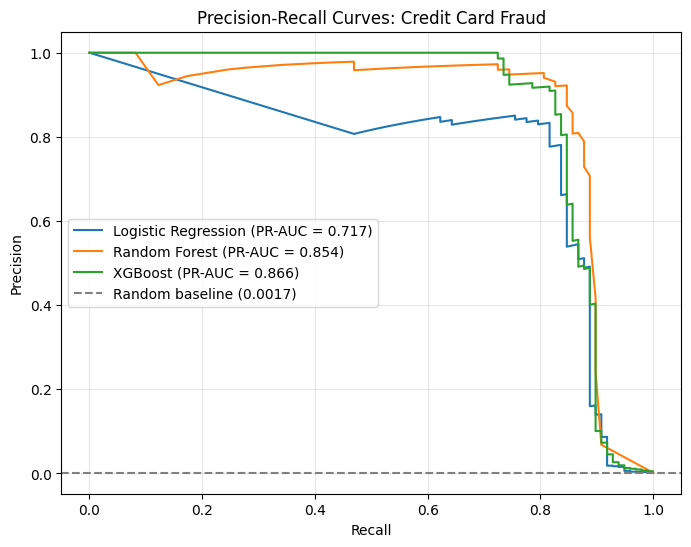

In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

models = {
    "Logistic Regression": y_prob,
    "Random Forest": rf_prob,
    "XGBoost": xgb_prob,
}

plt.figure(figsize=(8, 6))
for name, prob in models.items():
    prec, rec, _ = precision_recall_curve(y_test, prob)
    ap = average_precision_score(y_test, prob)
    plt.plot(rec, prec, label=f"{name} (PR-AUC = {ap:.3f})")

baseline = y_test.mean()
plt.axhline(baseline, linestyle="--", color="gray", label=f"Random baseline ({baseline:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves: Credit Card Fraud")
plt.legend()
plt.grid(alpha=0.3)
plt.show()